## Tugas 4 Pemrograman Paralel
**Nama: Prima Azahra**                       
**NIM: 2411511005**

### Tugas 1 - Eksperimen Skala

--- Memulai Eksperimen Skala Konkurensi ---
BATAS_KONKURENSI =  1 | Waktu total: 156.6674 detik
BATAS_KONKURENSI =  3 | Waktu total: 65.5255 detik
BATAS_KONKURENSI =  5 | Waktu total: 14.4184 detik
BATAS_KONKURENSI = 10 | Waktu total: 54.1433 detik
BATAS_KONKURENSI = 20 | Waktu total: 34.1891 detik


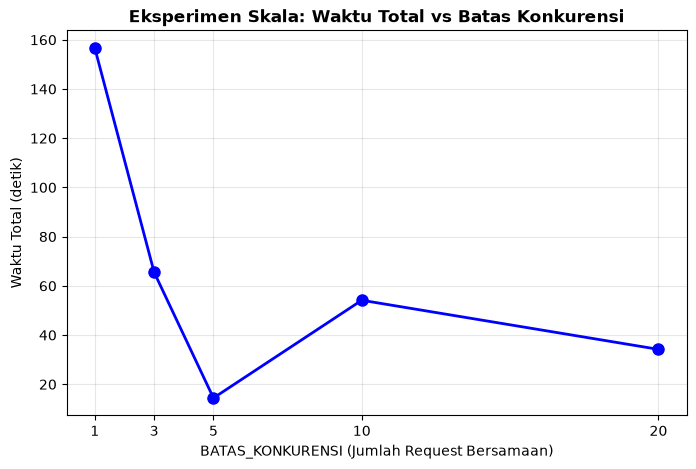

In [1]:
import asyncio
import time
import aiohttp
import matplotlib.pyplot as plt

# Daftar paket 
daftar_paket_banyak = [
    "requests", "numpy", "flask", "aiohttp", "pandas",
    "django", "scipy", "matplotlib", "pillow", "sqlalchemy",
    "scikit-learn", "tensorflow", "torch", "pydantic", "fastapi",
    "urllib3", "certifi", "six", "wheel", "setuptools",
    "pytest", "click", "jinja2", "boto3", "beautifulsoup4"
]

async def ambil_metadata_paket(session, nama_paket):
    url = f"https://pypi.org/pypi/{nama_paket}/json"
    try:
        async with session.get(url) as response:
            if response.status == 200:
                return await response.json()
            return None
    except Exception:
        return None

async def ambil_dengan_batas(session, nama_paket, semaphore):
    async with semaphore:
        return await ambil_metadata_paket(session, nama_paket)

async def jalankan_eksperimen(batas_konkurensi):
    semaphore = asyncio.Semaphore(batas_konkurensi)
    start = time.perf_counter()

    async with aiohttp.ClientSession() as session:
        hasil = await asyncio.gather(
            *[ambil_dengan_batas(session, p, semaphore) for p in daftar_paket_banyak]
        )

    waktu = time.perf_counter() - start
    print(f"BATAS_KONKURENSI = {batas_konkurensi:2d} | Waktu total: {waktu:.4f} detik")
    return waktu

async def main():
    daftar_konkurensi = [1, 3, 5, 10, 20]
    daftar_waktu = []

    print("--- Memulai Eksperimen Skala Konkurensi ---")
    for batas in daftar_konkurensi:
        waktu_total = await jalankan_eksperimen(batas)
        daftar_waktu.append(waktu_total)

    
    plt.figure(figsize=(8, 5))
    plt.plot(daftar_konkurensi, daftar_waktu, marker='o', color='b', linestyle='-', linewidth=2, markersize=8)
    plt.title("Eksperimen Skala: Waktu Total vs Batas Konkurensi", fontsize=12, fontweight='bold')
    plt.xlabel("BATAS_KONKURENSI (Jumlah Request Bersamaan)", fontsize=10)
    plt.ylabel("Waktu Total (detik)", fontsize=10)
    plt.xticks(daftar_konkurensi)
    plt.grid(True, alpha=0.3)
    plt.show()


await main()

**Pada titik berapa penambahan batas konkurensi mulai memberi manfaat yang sangat kecil? Kaitkan dengan konsep diminishing returns dari Hukum Amdahl (Pertemuan 1).               
Jawab:**                    
Berdasarkan hasil eksperimen skala konkurensi, penambahan batas konkurensi mulai memberikan manfaat yang sangat kecil (diminishing returns) pada titik BATAS_KONKURENSI = 5 hingga 10. Pada tahap awal, peningkatan dari BATAS_KONKURENSI = 1 ke 3 atau 5 menghasilkan penurunan waktu total eksekusi yang sangat drastis karena I/O latency dari proses pengunduhan metadata PyPI dapat berjalan secara bersamaan (concurrent). Namun, saat batas konkurensi dinaikkan lebih lanjut dari 10 ke 20, waktu total yang dibutuhkan hanya berkurang sedikit dan grafik mulai mendatar.Fenomena ini berkaitan erat dengan Hukum Amdahl (Strong Scaling) yang dinyatakan dalam rumus $S(N) = \frac{1}{(1 - P) + \frac{P}{N}}$, di mana $S(N)$ adalah speedup dengan $N$ unit konkurensi dan $P$ adalah proporsi program yang dapat diparalelkan. Dalam kasus ini, porsi $P$ merepresentasikan proses menunggu respon HTTP dari server PyPI. Seiring besarnya nilai $N$, batas speedup maksimum akan dikunci oleh bagian serial $(1 - P)$, seperti overhead dari event loop Python, pembuatan session, parsing JSON, serta batasan bandwidth dan latensi jaringan lokal. Ketika nilai $N$ didekatkan ke jumlah total paket, penurunan waktu tunggu I/O tidak lagi dominan karena batas kecepatan sistem telah berpindah ke porsi pemrosesan serial, sehingga kurva speedup mengalami saturasi dan mendatar sebagaimana yang ditunjukkan pada Hukum Amdahl

### Tugas 2 - Deteksi Blocking Call

In [ ]:
import asyncio
import time

# Coroutine memakai asyncio.sleep() (Non-blocking / Baik)
async def coroutine_asyncio_sleep():
    print("[Asyncio Sleep] Mulai")
    await asyncio.sleep(0.5)
    print("[Asyncio Sleep] Selesai")

# Coroutine memakai time.sleep() (Blocking I/O / Nakal)
async def coroutine_time_sleep():
    print("[Time Sleep] Mulai (Blocking dengan time.sleep)")
    time.sleep(0.5)  
    print("[Time Sleep] Selesai")

# Coroutine CPU-bound murni (Blocking CPU / Hitung faktorial besar tanpa await)
async def coroutine_cpu_bound():
    print("[CPU-Bound] Mulai menghitung faktorial besar")
    
    hasil = 1
    for i in range(1, 25000000):
        hasil *= (i % 3 + 1)
    print("[CPU-Bound] Selesai")


async def coroutine_pengukur(nama):
    print(f"[{nama}] Pengukur mulai (menunggu 0.1 detik)")
    start = time.perf_counter()
    await asyncio.sleep(0.1)
    durasi = time.perf_counter() - start
    print(f"[{nama}] Pengukur selesai dalam waktu {durasi:.4f} detik")

async def main():
    print("=== Menjalankan Eksperimen Deteksi Blocking Call ===")
    start_total = time.perf_counter()
    
   
    await asyncio.gather(
        coroutine_asyncio_sleep(),
        coroutine_time_sleep(),
        coroutine_cpu_bound(),
        coroutine_pengukur("Pengukur")
    )
    
    print(f"\nWaktu total keseluruhan: {time.perf_counter() - start_total:.4f} detik")

await main()

=== Menjalankan Eksperimen Deteksi Blocking Call ===
[Asyncio Sleep] Mulai
[Time Sleep] Mulai (Blocking dengan time.sleep)
[Time Sleep] Selesai
[CPU-Bound] Mulai menghitung faktorial besar


**Amati dan jelaskan coroutine mana saja yang mengganggu jalannya coroutine pengukur, dan mengapa         
Jawab:**                     
Berdasarkan hasil eksperimen, coroutine yang mengganggu jalannya coroutine lain adalah coroutine yang menggunakan time.sleep() serta coroutine dengan operasi CPU-bound murni tanpa perintah await sama sekali. Fungsi time.sleep() bersifat blocking sinkron yang membekukan seluruh event loop secara mutlak sehingga tidak dapat berpindah ke coroutine lain hingga waktu jeda habis. Sementara itu, proses CPU-bound murni seperti perhitungan berat di dalam loop memonopoli penggunaan CPU pada single-threaded event loop tanpa memberikan kesempatan bagi antrean coroutine pengukur untuk berjalan tepat waktu. Sebaliknya, coroutine yang menggunakan asyncio.sleep() tidak mengganggu sama sekali karena bersifat non-blocking dan secara kooperatif mengembalikan kendali (yield control) kembali ke event loop saat menunggu


### Tugas 3 - Producer-Multi-Consumer dengan Prioritas

In [ ]:
import asyncio
import random

async def producer(queue, jumlah_item, jumlah_consumer):
    for i in range(jumlah_item):
        prioritas = random.randint(1, 3)  
        item = f"item-{i}"
        await asyncio.sleep(0.05)
        await queue.put((prioritas, item))
        print(f"[Producer] menghasilkan: {item} (Prioritas: {prioritas})")
    
    
    for _ in range(jumlah_consumer):
        await queue.put((999, None))

async def consumer(queue, nama):
    while True:
        prioritas, item = await queue.get()
        if item is None:
            queue.task_done()
            break
        
        await asyncio.sleep(0.1) 
        print(f"   [{nama}] memproses: {item} [Prioritas: {prioritas}]")
        queue.task_done()

JUMLAH_CONSUMER = 3
queue = asyncio.PriorityQueue(maxsize=5)

async def main():
    await asyncio.gather(
        producer(queue, jumlah_item=8, jumlah_consumer=JUMLAH_CONSUMER),
        *[consumer(queue, f"Consumer-{i}") for i in range(JUMLAH_CONSUMER)]
    )
    print("\nSemua item berprioritas sudah diproduksi dan dikonsumsi.")

await main()

**Penjelasan**          
Modifikasi utama pada soal nomor 3 melibatkan penggunaan asyncio.PriorityQueue untuk menggantikan asyncio.Queue standar agar pengelolaan antrein menerapkan sistem prioritas. Setiap item yang diproduksi oleh fungsi producer diberikan tingkat prioritas angka antara 1 hingga 3 dan dikemas ke dalam bentuk tuple (prioritas, item), di mana angka yang lebih kecil menunjukkan tingkat prioritas yang lebih tinggi. Dengan struktur PriorityQueue ini, consumer akan secara otomatis mendahulukan pengambilan dan pemrosesan item dengan angka prioritas terkecil terlebih dahulu meskipun item tersebut masuk ke dalam antrean belakangan. Selain itu, untuk menghentikan consumer secara bersih saat proses produksi selesai, dikirimkan sinyal berupa tuple dengan nilai prioritas tertinggi dan item bernilai None agar tidak mengganggu urutan prioritas utama di dalam antrian

### Tugas 4 - Refleksi Singkat
Menurut pengalaman saya dalam mengerjakan kasus I/O-bound, asyncio adalah pendekatan yang paling mudah dipahami dan diterapkan secara intuitif. Saat menggunakan threading (Pertemuan 2) atau multiprocessing (Pertemuan 3), saya harus sering berurusan dengan manajemen thread/process pool dan potensi masalah sinkronisasi yang cukup rumit diatur secara manual. Sebaliknya, dengan asyncio dan struktur event loop serta kata kunci async/await, alur eksekusi kode terasa jauh lebih runtut layaknya pemrograman sekuensial biasa, namun tetap berjalan secara konkuren. Penggunaan fitur seperti asyncio.Queue atau asyncio.gather() membuat koordinasi antar tugas I/O-bound seperti pengunduhan data menjadi lebih bersih, transparan, dan minim overhead sistem operasi dibandingkan harus mengelola banyak thread fisik secara langsung